# Deep Learning MLP with PyTorch

The goal of the Lab is to use (train and test) an MLP for a multi-class classification task on real data.

In this notebook :

- download the data from the internet.
- process the data using Pandas:
    - load the .xls file, split into X and y, split into train and eval-set.
- create a pytorch Dataset to allow getting them on the fly.
- write an MLP model using the `nn.Module` class formalism.
- write a loop over epochs in wich you train the model over mini-batch of the training-set and evaluate over the eval-set.
    - display at each epoch the losses and accuracies over training and test data.
- plot the losses and accuracies evoluation over epochs.

You will use the 'Dry Bean Dataset' descibed here https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset and downloadable here https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset.zip.

Every line of code was written by me, without AI-generated code. I used AI as a learning tool to ask questions, understand concepts.

# Import packages

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import urllib.request

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Data acquisition

Get the Dry Bean Dataset

Documentation: https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset

URL: https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset.zip

In [26]:
!rm DryBeanDataset.zip
!rm -rf ./DryBeanDataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset.zip"
urllib.request.urlretrieve(url, "DryBeanDataset.zip")

!unzip DryBeanDataset.zip

Archive:  DryBeanDataset.zip
   creating: DryBeanDataset
  inflating: DryBeanDataset/Dry_Bean_Dataset.arff  
  inflating: DryBeanDataset/Dry_Bean_Dataset.txt  
  inflating: DryBeanDataset/Dry_Bean_Dataset.xlsx  


# Data preprocessing (using pandas and sklearn)

Process the data
* load the .xls file data using `pandas` (read_excel)
* split into X (all columns except `Class`) and y (column `Class`) using `pandas`
* convert y to integer using `sklearn` (LabelEncoder)
* split into train and valid datasets using `sklearn` (train_test_split), we use a 80\% train, 20\% validation split
* standardize the X of train and valid using `sklearn` (StandardScaler)



In [27]:
data_file = 'DryBeanDataset/Dry_Bean_Dataset.xlsx'
frame =pd.read_excel(data_file)


In [28]:
type(frame.columns) #type de la frame.columns type pandas.Index on paut faire de la comparaison vectorisé
frame.columns.dtype # type of the element of frame.columns
y = frame.loc[:,"Class"]
y
nb_class = y.unique().count()

In [29]:
def load_and_preprocess(data_file):
    # --- 1

    frame = pd.read_excel(data_file)

    #X = frame[[name for name in frame.columns if name!="Class"]] #solution 1 pour enlever toutes les column sauf 1
    #X = frame.loc[:,[name for name in frame.columns if name!="Class"]] #solution 2 with .loc better understanding
    X = frame.loc[:,frame.columns != "Class"] #solution 3 using comparaison vectorielle
    y = frame.loc[:,"Class"]

    le = LabelEncoder()
    # le.fit(y)
    # y = le.transform(y)
    y = le.fit_transform(y) #acceptable for all the dataset for this kind of encoder but either be careful with the data-leakage

    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

    ss = StandardScaler() #need the column to be integer
    X_train, X_valid = ss.fit_transform(X_train), ss.transform(X_valid) #dataleakage be careful only transform on X_valid and this return some numpy arrays
    
    return X_train, X_valid, y_train, y_valid, len(np.unique(y))

data_file = 'DryBeanDataset/Dry_Bean_Dataset.xlsx'
X_train, X_valid, y_train, y_valid, num_classes = load_and_preprocess(data_file)

In [30]:
print(X_train.shape)
print(y_train.shape)
print(set(y_train))

print(X_valid.shape)
print(y_valid.shape)
print(set(y_valid))

(10888, 16)
(10888,)
{np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)}
(2723, 16)
(2723,)
{np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)}


# Write the pytorch Dataset and Dataloader

create a pytorch Dataset to allow getting X and y on the fly
* we need to convert the data from numpy to torch-tensors

In [31]:
# --- 2

#torch.from_numpy(X) → partage la mémoire avec NumPy
#torch.tensor(X) → crée une copie indépendante

class BeanDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float() #transform en 32 pour les réseaux de neuronnes mieux
        self.y = torch.from_numpy(y).long() #chach that the term is int (.long())

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx,:], self.y[idx]

train_dataset = BeanDataset(X_train, y_train)
valid_dataset = BeanDataset(X_valid, y_valid)

# DataLoaders handle batching, shuffling, and multi-process loading.
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False)

# Write the MLP model using `nn.Module`

The MLP model as the following architecture: `input_dim -> 128 -> 64 -> 64 -> output_dim`
* `output_dim`corresponds to the number of classes
* we put a `ReLU` between each layer
* keep the logits 

In [32]:
# --- 3
class MLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim,128)
        self.fc2 = nn.Linear(128,64)
        self.fc3 = nn.Linear(64,64)
        self.fc4 = nn.Linear(64,output_dim)
        self.relu = nn.ReLU()
        

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        hat_y = self.fc4(x) # no softmax because cross entropy do the calculation 

        return hat_y

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MLP(X_train.shape[1], num_classes).to(device) 

In [9]:
print(model)

MLP(
  (fc1): Linear(in_features=16, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=64, bias=True)
  (fc4): Linear(in_features=64, out_features=7, bias=True)
  (relu): ReLU()
)


# Define the loss to be minimized and the optimizer

We use a loss named Cross-entropy since we deal multi-class classification.

We optimize the model using an `Adam` optimizer using a learning rate of 0.001.

In [33]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Write the main loop

We write the main loop over epochs.
For each epoch
* we train the model
    * we set the model in train mode using `model.train()`
    * we loop over mini-batches of training data: zero_grad(), forward, loss, backward, step
    * we compute the current accuracy
* we evaluate the currently trained model on the validation data
    * we set the model in train mode using `model.eval()`
    * we loop over mini-batches of validation data: forward, loss
    * we compute the current loss and accuracy
* we store and print the loss and accuracy for training and validation data

In [11]:
epochs = 100
history = {'train_loss': [], 'valid_loss': [], 'train_acc': [], 'valid_acc': []}

# --- 4
for epoch in range(epochs):

    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad() #reinitialise le grad à 0 

        pred = model(batch_X) # call __call__ it deals some things before forward and then compute forward
        loss = criterion(pred, batch_y)

        loss.backward() #compute the gradient and it is easy because linear, known by the model
        optimizer.step() # adjuste the weights

        train_loss += loss.item() * len(batch_y) #loss renvoie la moyenne des loss
        train_correct += (pred.argmax(dim=1) == batch_y).sum().item()
        train_total += len(batch_y)
    
    history['train_loss'].append(train_loss / train_total)
    history['train_acc'].append(train_correct / train_total)
    
    model.eval()
    valid_loss = 0
    valid_correct = 0
    valid_total = 0

    with torch.no_grad():
        for batch_X, batch_y in valid_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            pred = model(batch_X)
            loss = criterion(pred, batch_y)

            valid_loss += loss.item() * len(batch_y)
            valid_correct += (pred.argmax(dim=1) == batch_y).sum().item()
            valid_total += len(batch_y)

    history['valid_loss'].append(valid_loss / valid_total)
    history['valid_acc'].append(valid_correct / valid_total)

    if epoch%5 == 0:
        print(f"after {epoch} epochs", "Train loss :", round(history['train_loss'][-1], 4), "Valid loss :", round(history['valid_loss'][-1], 4), "Train accuracy :", round(history['train_acc'][-1], 4),"Valid accuracy :", round(history['valid_acc'][-1], 4))


                

    ...

after 0 epochs Train loss : 0.6202 Valid loss : 0.2311 Train accuracy : 0.7876 Valid accuracy : 0.9119
after 5 epochs Train loss : 0.1959 Valid loss : 0.2014 Train accuracy : 0.9276 Valid accuracy : 0.9269
after 10 epochs Train loss : 0.1872 Valid loss : 0.191 Train accuracy : 0.9296 Valid accuracy : 0.9317
after 15 epochs Train loss : 0.1787 Valid loss : 0.1921 Train accuracy : 0.9318 Valid accuracy : 0.931
after 20 epochs Train loss : 0.1778 Valid loss : 0.1893 Train accuracy : 0.9315 Valid accuracy : 0.9302
after 25 epochs Train loss : 0.1734 Valid loss : 0.1874 Train accuracy : 0.9352 Valid accuracy : 0.9357
after 30 epochs Train loss : 0.1702 Valid loss : 0.1919 Train accuracy : 0.9337 Valid accuracy : 0.9288
after 35 epochs Train loss : 0.1648 Valid loss : 0.1992 Train accuracy : 0.9373 Valid accuracy : 0.9284
after 40 epochs Train loss : 0.1638 Valid loss : 0.1913 Train accuracy : 0.9378 Valid accuracy : 0.9335
after 45 epochs Train loss : 0.1614 Valid loss : 0.1904 Train accura

# Plot the loss and accuracy evolution over epoches for train and test data

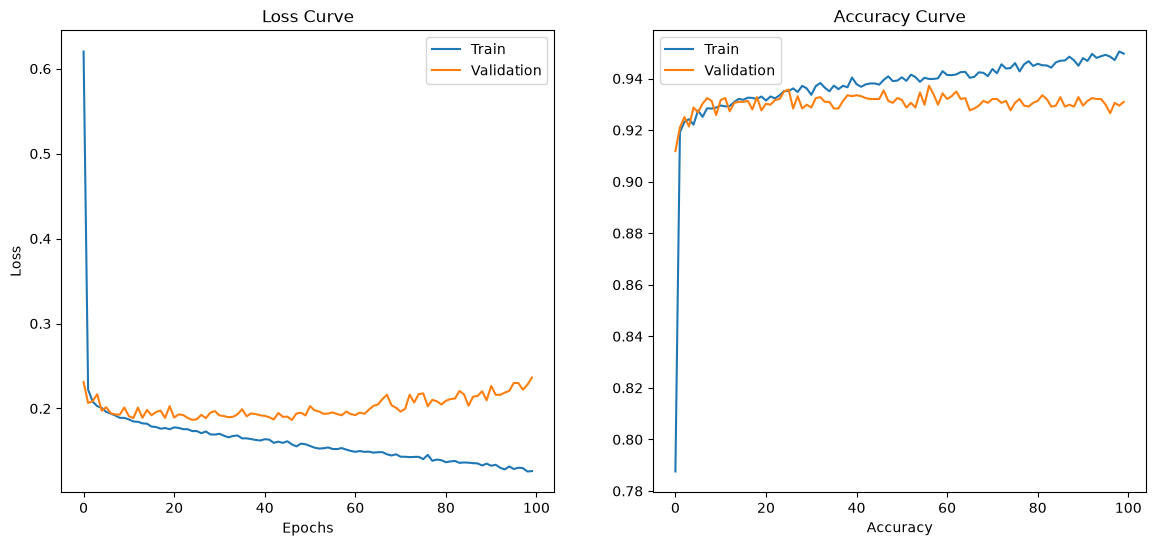

In [12]:
# --- 5
fig,axes = plt.subplots(ncols=2,nrows=1, sharex = 'row', figsize = (14,6))

axes[0].plot(history['train_loss'], label="Train")
axes[0].plot(history['valid_loss'], label="Validation")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss Curve")
axes[0].legend()

axes[1].plot(history['train_acc'], label="Train")
axes[1].plot(history['valid_acc'], label="Validation")
axes[1].set_xlabel("Epochs")
axes[1].set_xlabel("Accuracy")
axes[1].set_title("Accuracy Curve")
axes[1].legend()

plt.show()


# Early-stopping

In the above, we start doing over-fitting (the loss still decreases for the training data but starts increasing for the validation data). We should stop before this. This is named **early-stopping**. Write a test in the training loop which stop the training when the validation-loss starts increasing.

In [42]:
model = MLP(X_train.shape[1], num_classes).to(device) 
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# --- 6
epochs = 200
history = {'train_loss': [], 'valid_loss': [], 'train_acc': [], 'valid_acc': []}
early_stop = 5
count = 0
min_valid_loss =  float('inf')
# --- 4
for epoch in range(epochs):

    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad() #reinitialise le grad à 0 

        pred = model(batch_X) # call __call__ it deals some things before forward and then compute forward
        loss = criterion(pred, batch_y)

        loss.backward() #compute the gradient and it is easy because linear, known by the model
        optimizer.step() # adjuste the weights

        train_loss += loss.item() * len(batch_y) #loss renvoie la moyenne des loss
        train_correct += (pred.argmax(dim=1) == batch_y).sum().item()
        train_total += len(batch_y)
    
    history['train_loss'].append(train_loss / train_total)
    history['train_acc'].append(train_correct / train_total)
    
    model.eval()
    valid_loss = 0
    valid_correct = 0
    valid_total = 0

    with torch.no_grad():
        for batch_X, batch_y in valid_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            pred = model(batch_X)
            loss = criterion(pred, batch_y)

            valid_loss += loss.item() * len(batch_y)
            valid_correct += (pred.argmax(dim=1) == batch_y).sum().item()
            valid_total += len(batch_y)

    history['valid_loss'].append(valid_loss / valid_total)
    history['valid_acc'].append(valid_correct / valid_total)
    #early stopping

    if min_valid_loss > history["valid_loss"][-1] : 
        min_valid_loss = history["valid_loss"][-1]
        count = 0
    else : 
        count += 1
        if count == early_stop :
            print(f"early stop at {epoch} epochs")
            break 
        else :
            continue

    if epoch%5 == 0:
        print(f"after {epoch} epochs", "Train loss :", round(history['train_loss'][-1], 4), "Valid loss :", round(history['valid_loss'][-1], 4), "Train accuracy :", round(history['train_acc'][-1], 4),"Valid accuracy :", round(history['valid_acc'][-1], 4))

#to be continue which weights to select ? the last one or the ones of the minimun. 

after 0 epochs Train loss : 0.6548 Valid loss : 0.2342 Train accuracy : 0.809 Valid accuracy : 0.9177
after 5 epochs Train loss : 0.1952 Valid loss : 0.1931 Train accuracy : 0.9258 Valid accuracy : 0.9317
early stop at 17 epochs


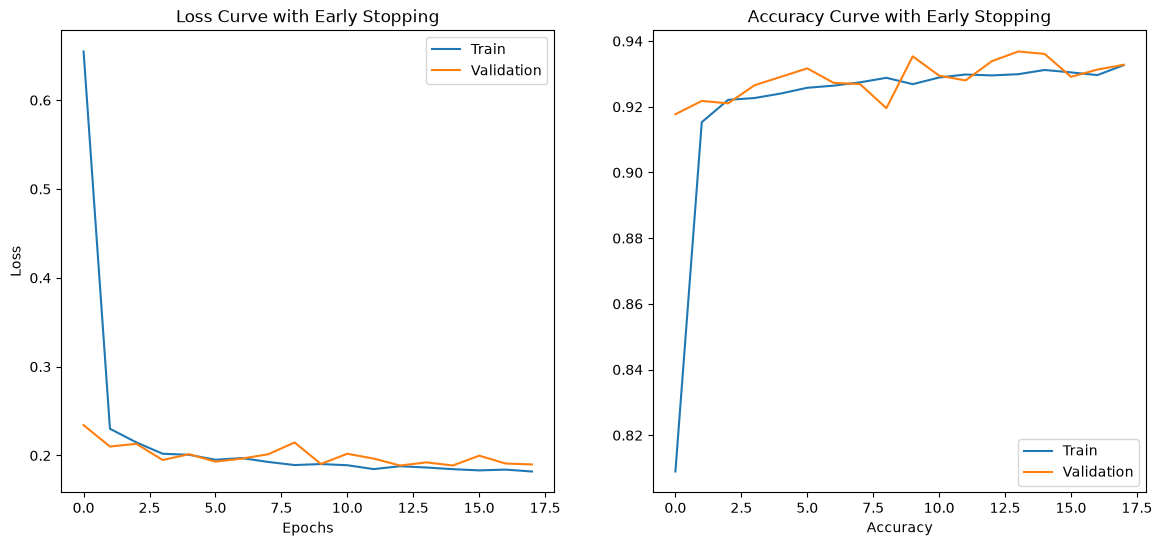

In [46]:
# --- 5
fig,axes = plt.subplots(ncols=2,nrows=1, sharex = 'row', figsize = (14,6))

axes[0].plot(history['train_loss'], label="Train")
axes[0].plot(history['valid_loss'], label="Validation")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss Curve with Early Stopping")
axes[0].legend()

axes[1].plot(history['train_acc'], label="Train")
axes[1].plot(history['valid_acc'], label="Validation")
axes[1].set_xlabel("Epochs")
axes[1].set_xlabel("Accuracy")
axes[1].set_title("Accuracy Curve with Early Stopping")
axes[1].legend()

plt.show()